# Learned P/S phase picking on STEAD traces

**Question:** What changes when a frozen three-component neural picker replaces a fixed STA/LTA onset rule, and what can these selected traces actually establish?

**Level 3 · Seismology and model evaluation · 60–90 min**

Prerequisites: waveform QC and first-arrival picking; held-out evaluation and class-conditional metrics.

## Objectives

- Reconstruct the normalized ENZ input, N/P/S output and fixed threshold/phase-separation rules.
- Run the released browser ONNX bytes locally on every QC-valid trace in the preselected 24-record display set.
- Compare learned M13 and fixed M08 STA/LTA on identical analyst-referenced inputs.
- Distinguish the descriptive 23-trace subset from the frozen 6,000-trace test benchmark.

## Setup

Use the repository-pinned research environment. The ONNX inference itself runs in the separate `.venv-pipeline` because that environment contains the locked model runtime. From the repository root, install the notebook packages with:

```text
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 pandas==2.2.3
```

Set `CAOS_TEMP_ROOT` to a writable scratch directory before executing. The notebook writes derived analysis there and keeps all downloaded or generated trace arrays out of the repository.

In [1]:
# Report pinned runtime and verify selected case counts before analysis.
from importlib.metadata import version
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
assets = root / "data/derived/phase/browser-assets/stead"
manifest = json.loads((assets / "manifest.json").read_text(encoding="utf-8"))
benchmark = json.loads((assets / "benchmark.json").read_text(encoding="utf-8"))
print("Notebook runtime:", {name: version(name) for name in ["numpy", "scipy", "matplotlib", "pandas"]})
print("Assets:", len(manifest["records"]), "selected;",
      sum(row["status"] == "qc-valid" for row in manifest["records"]), "valid;",
      sum(row["status"] == "qc-rejected" for row in manifest["records"]), "rejected")
print("Locked benchmark:", benchmark["selected"], "selected;", benchmark["valid"],
      "QC-valid;", benchmark["qc_rejected"], "QC-rejected")
assert manifest["browser_parity_verified"] is False
assert manifest["selection"]["selected_before_heldout_scoring"] is True
assert benchmark["metrics_include_qc_failures_as_unpicked"] is True

Notebook runtime: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8', 'pandas': '3.0.6'}
Assets: 24 selected; 23 valid; 1 rejected
Locked benchmark: 6000 selected; 5926 QC-valid; 74 QC-rejected


## Data

The browser package contains 24 records selected before test scoring: 23 valid waveforms and one QC-rejected noise trace. The rejected row has no waveform and is never sent to the model. The valid traces allow inspection of measured signal and failure modes, but this selected subset is not representative and cannot support a population accuracy claim.

The separate frozen benchmark covers 6,000 event/station-disjoint STEAD test traces; its locked M08/M13 aggregate metrics count QC failures as unpicked. This lesson recomputes the selected subset with ONNX Runtime CPU and reports the aggregate benchmark beside it. It does not run the private PyTorch oracle comparison and does not set `browser_parity_verified=true`.

## Method

Each 60 s record is sampled at 100 Hz and stored as three component-major arrays in **E, N, Z** order. For raw counts $x_c$, the product transform is $z_c=(x_c-\operatorname{mean}_{64}(x_c))/\max_t|x_c-\operatorname{mean}_{64}(x_c)|$. The model maps $z\in\mathbb{R}^{1	imes3	imes6000}$ to sample scores $q\in[0,1]^{1	imes3	imes6000}$ ordered **N, P, S**. A phase pick is the global maximum if it reaches 0.8; S is suppressed if it occurs less than 0.4 s after P. These are decision thresholds, not calibrated uncertainty.

The analysis below verifies the manifest, model and trace hashes, then applies the exact released M08 and M13 implementations to identical waveforms. Matched-pick evaluation uses the locked ±0.5 s tolerance. An analyst arrival is a reference time, not geological ground truth; STA/LTA trigger order can also confuse S with another onset.

In [2]:
# Execute the version-pinned local M08/M13 pipeline. All derived trace arrays stay under CAOS_TEMP_ROOT.
work = Path(os.environ["CAOS_TEMP_ROOT"]) / "m13-display-subset"
work.mkdir(parents=True, exist_ok=True)
result_path = work / "analysis.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engines = [engine_root / ".venv-pipeline/Scripts/python.exe", engine_root / ".venv-pipeline/bin/python"]
engine = next((candidate for candidate in engines if candidate.is_file()), None)
if engine is None:
    raise RuntimeError("The repository-pinned .venv-pipeline with onnxruntime and torch is required")
run = subprocess.run(
    [str(engine), str(engine_root / "data-pipeline/stead_phase_browser_subset.py"),
     "--assets", str(assets), "--output", str(result_path)],
    cwd=engine_root, capture_output=True, text=True, timeout=240,
)
if run.returncode:
    raise RuntimeError("M13 display-subset pipeline failed: " + run.stderr[-3000:])
analysis = json.loads(result_path.read_text(encoding="utf-8"))
assert analysis["schema"] == "caos.m13-browser-display-subset-analysis.v1"
assert (analysis["selected_count"], analysis["qc_valid_count"], analysis["qc_rejected_count"]) == (24, 23, 1)
assert analysis["status"].startswith("recomputed-23-trace-descriptive-subset")
print(run.stdout)
print("Verified manifest:", analysis["manifest_sha256"])
print("Verified model:", analysis["model_sha256"])

{
  "status": "recomputed-23-trace-descriptive-subset; not full benchmark or browser parity",
  "selected_count": 24,
  "qc_valid_count": 23,
  "qc_rejected_count": 1,
  "noise_valid_count": 7,
  "manifest_sha256": "d4d2b5b1a98d3a7a2077baab7750c8a96e4b5152b6930e4a09ae4bdc97db8394",
  "model_sha256": "4e5962ed0a9037e545991c218ae770ae7aff2c01f1e6a919c338705780ce5f4c",
  "display_subset_metrics": {
    "M08": {
      "P": {
        "reference_count": 16,
        "correct_within_0p5s": 2,
        "missed": 0,
        "outside_tolerance": 14,
        "false_without_reference": 7,
        "precision_at_0p5s": 0.08695652173913043,
        "recall_at_0p5s": 0.125,
        "f1_at_0p5s": 0.10256410256410256,
        "valid_noise_false_pick_rate": 1.0,
        "picked_reference_count": 16,
        "timing_bias_median_s": -4.025,
        "timing_absolute_median_s": 4.025,
        "timing_absolute_p90_s": 5.905
      },
      "S": {
        "reference_count": 16,
        "correct_within_0p5s": 0,
 

## State of the art

PhaseNet popularized per-sample probability curves for P and S arrivals from three-component waveforms, while STEAD provides a large, diverse dataset of earthquake and noise traces with analyst picks. The project checkpoint shown here is an independently trained PhaseNet-family model; it is not the official PhaseNet checkpoint. Comparing both algorithms on the same input, and separating event/station-held-out population evidence from a selected display set, is essential to avoid conflating an attractive probability curve with demonstrated generalization.

## Results

Run the cells to inspect real recorded waveforms, detector outputs, cohort metrics and per-trace residuals. Interpret differences alongside the selected-case counts and QC decision. The locked benchmark is the only population-level result shown here.

### Inspect a measured record

The upper panel overlays the three normalized measured components. Vertical lines distinguish analyst references, M13 predictions and M08 triggers. The lower panel shows the actual N/P/S score curves emitted by the released ONNX model. Analyst times are used only for display and evaluation, never by either detector.

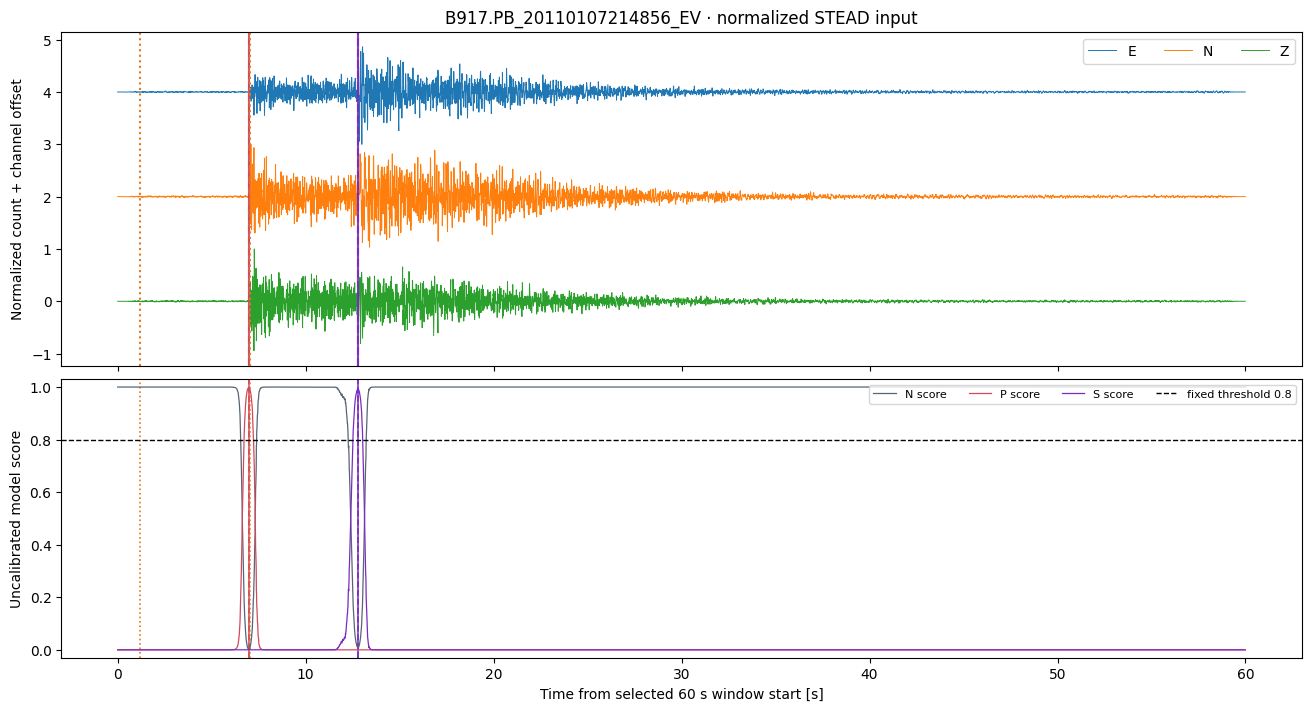

Analyst references (not ground truth): 7.0 12.77 s
M13 picks: 6.99 12.780000000000001 s; M08 picks: 1.19 7.0200000000000005 s


In [3]:
# Plot measured components and the exact ONNX probability curves with reference and detector picks.
example = analysis["example"]
wave = np.asarray(example["waveform_enz"], dtype=float)
prob = np.asarray(example["probabilities_nps"], dtype=float)
time_s = np.arange(len(wave)) / 100
fig, (ax_wave, ax_prob) = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                                       gridspec_kw={"height_ratios": [1.2, 1]}, constrained_layout=True)
for index, name in enumerate(("E", "N", "Z")):
    ax_wave.plot(time_s, wave[:, index] + 2 * (2 - index), lw=0.7, label=name)
ax_wave.set_ylabel("Normalized count + channel offset")
ax_wave.set_title(f"{example['trace_id']} · normalized STEAD input")
ax_wave.legend(ncol=3, loc="upper right")
for phase, color in (("P", "#d1495b"), ("S", "#7b2cbf")):
    reference = example[f"analyst_{phase.lower()}_s"]
    learned = example[f"m13_{phase.lower()}_s"]
    classical = example[f"m08_{phase.lower()}_s"]
    if reference is not None:
        ax_wave.axvline(reference, color=color, ls="--", lw=1.5, label=f"analyst {phase}")
        ax_prob.axvline(reference, color=color, ls="--", lw=1.2)
    if learned is not None:
        ax_wave.axvline(learned, color=color, ls="-", lw=1.5, alpha=0.9, label=f"M13 {phase}")
        ax_prob.axvline(learned, color=color, ls="-", lw=1.2, alpha=0.9)
    if classical is not None:
        ax_wave.axvline(classical, color="#e07a1f", ls=":", lw=1.5, label=f"M08 {phase}")
        ax_prob.axvline(classical, color="#e07a1f", ls=":", lw=1.2)
for index, name, color in ((0, "N", "#576574"), (1, "P", "#d1495b"), (2, "S", "#7b2cbf")):
    ax_prob.plot(time_s, prob[:, index], lw=0.9, label=f"{name} score", color=color)
ax_prob.axhline(0.8, color="black", ls="--", lw=1, label="fixed threshold 0.8")
ax_prob.set(xlabel="Time from selected 60 s window start [s]", ylabel="Uncalibrated model score", ylim=(-0.03, 1.03))
ax_prob.legend(ncol=4, loc="upper right", fontsize=8)
plt.show()
print("Analyst references (not ground truth):", example["analyst_p_s"], example["analyst_s_s"], "s")
print("M13 picks:", example["m13_p_s"], example["m13_s_s"], "s; M08 picks:", example["m08_p_s"], example["m08_s_s"], "s")

### Compare cohorts and error modes

These grouped plots place the frozen 6,000-trace test metrics beside the selected 23-valid-trace display subset. The noise false-pick panel has 931 valid-noise cases in the full test, but only seven here. Read the smaller cohort as a trace-inspection aid, not as validation of a population-level improvement.

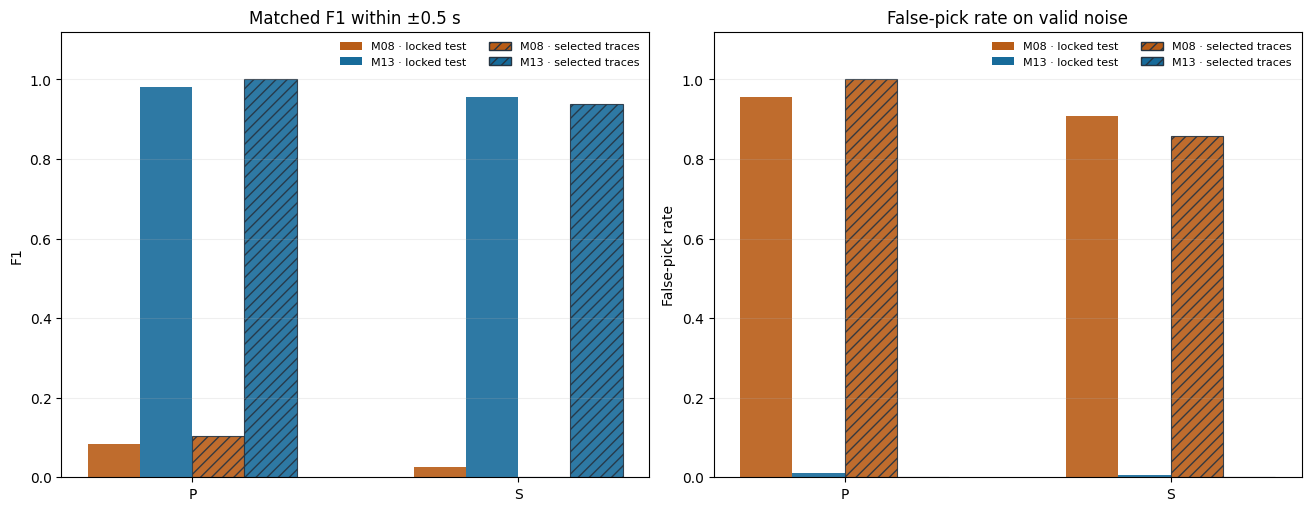

,cohort,method,P F1,S F1,P noise false rate,S noise false rate
0,"Locked test (n=6,000)",M08,0.083,0.025,0.957,0.908
1,"Locked test (n=6,000)",M13,0.981,0.955,0.011,0.006
2,Selected traces (n=23),M08,0.103,0.000,1.000,0.857
3,Selected traces (n=23),M13,1.000,0.938,0.000,0.000


In [4]:
# Compare locked benchmark aggregates with descriptive display-subset metrics.
cohorts = {
    "Locked test (n=6,000)": analysis["locked_6000_test_metrics"],
    "Selected traces (n=23)": analysis["display_subset_metrics"],
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
phases = ["P", "S"]
methods = ["M08", "M13"]
colors = {"M08": "#b85c16", "M13": "#176b9a"}
width = 0.16
x = np.arange(2)
for cohort_index, (cohort_name, metrics) in enumerate(cohorts.items()):
    cohort_shift = (cohort_index - 0.5) * 2 * width
    for method_index, method in enumerate(methods):
        shift = cohort_shift + (method_index - 0.5) * width
        f1_values = [metrics[method][phase]["f1_at_0p5s"] for phase in phases]
        false_values = [metrics[method][phase]["valid_noise_false_pick_rate"] for phase in phases]
        style = {} if cohort_index == 0 else {"hatch": "///", "edgecolor": "#263442", "linewidth": 0.8}
        axes[0].bar(x + shift, f1_values, width, color=colors[method], alpha=0.9, **style)
        axes[1].bar(x + shift, false_values, width, color=colors[method], alpha=0.9, **style)
axes[0].set(title="Matched F1 within ±0.5 s", ylabel="F1", xticks=x, xticklabels=phases, ylim=(0, 1.12))
axes[1].set(title="False-pick rate on valid noise", ylabel="False-pick rate", xticks=x, xticklabels=phases, ylim=(0, 1.12))
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=colors["M08"], label="M08 · locked test"),
    Patch(facecolor=colors["M13"], label="M13 · locked test"),
    Patch(facecolor=colors["M08"], hatch="///", edgecolor="#263442", label="M08 · selected traces"),
    Patch(facecolor=colors["M13"], hatch="///", edgecolor="#263442", label="M13 · selected traces"),
]
for axis in axes:
    axis.grid(axis="y", alpha=0.2)
    axis.legend(handles=legend_handles, fontsize=8, frameon=False, ncol=2, loc="upper right")
plt.show()

rows = []
for cohort_name, metrics in cohorts.items():
    for method in methods:
        rows.append({"cohort": cohort_name, "method": method,
                     "P F1": metrics[method]["P"]["f1_at_0p5s"],
                     "S F1": metrics[method]["S"]["f1_at_0p5s"],
                     "P noise false rate": metrics[method]["P"]["valid_noise_false_pick_rate"],
                     "S noise false rate": metrics[method]["S"]["valid_noise_false_pick_rate"]})
display(pd.DataFrame(rows).round(3))

### Audit individual traces

The table exposes misses, early/late arrivals and noise alarms by trace. Residuals are prediction minus analyst reference; blank values mean a phase was not picked or not referenced. The ±0.5 s matching window is an evaluation convention, not a claim about analyst precision.

In [5]:
# Calculate prediction-minus-reference residuals for each selected trace.
trace_rows = pd.DataFrame(analysis["traces"])
for phase in ("P", "S"):
    trace_rows[f"M13 {phase} residual [s]"] = trace_rows[f"m13_{phase.lower()}_s"] - trace_rows[f"analyst_{phase.lower()}_s"]
    trace_rows[f"M08 {phase} residual [s]"] = trace_rows[f"m08_{phase.lower()}_s"] - trace_rows[f"analyst_{phase.lower()}_s"]
display(trace_rows[["trace_id", "category", "analyst_p_s", "m08_p_s", "m13_p_s",
                     "M08 P residual [s]", "M13 P residual [s]", "analyst_s_s", "m08_s_s", "m13_s_s",
                     "M08 S residual [s]", "M13 S residual [s]"]].round(2))

,trace_id,category,analyst_p_s,m08_p_s,m13_p_s,M08 P residual [s],M13 P residual [s],analyst_s_s,m08_s_s,m13_s_s,M08 S residual [s],M13 S residual [s]
0,B917.PB_20110107214856_EV,earthquake_local,7.0,1.19,6.99,-5.81,-0.01,12.77,7.02,12.78,-5.75,0.01
1,B093.PB_20111211064029_EV,earthquake_local,7.0,1.19,7.02,-5.81,0.02,9.32,7.02,9.35,-2.30,0.03
2,BBGB.NC_20110929163129_EV,earthquake_local,9.0,3.00,8.99,-6.00,-0.01,12.60,9.00,12.58,-3.60,-0.02
3,BBGB.NC_20110309162307_EV,earthquake_local,5.0,1.59,5.00,-3.41,0.00,8.91,3.42,9.12,-5.49,0.21
4,BBR.CI_20160306010500_EV,earthquake_local,4.0,1.19,4.00,-2.81,0.00,13.43,4.07,13.82,-9.36,0.39
5,LMR2.CI_20130325173024_EV,earthquake_local,5.0,1.22,4.96,-3.78,-0.04,10.88,1.67,10.82,-9.21,-0.06
6,BDM.BK_20160112043452_EV,earthquake_local,7.0,1.19,6.99,-5.81,-0.01,11.08,7.03,11.20,-4.05,0.12
7,SAO.BK_20131207235848_EV,earthquake_local,7.0,1.23,7.00,-5.77,0.00,10.55,1.70,10.62,-8.85,0.07
8,CRY.AZ_20120529154839_EV,earthquake_local,6.0,1.73,6.00,-4.27,0.00,9.34,4.62,9.43,-4.72,0.09
9,CRY.AZ_20160919195008_EV,earthquake_local,9.0,1.19,9.02,-7.81,0.02,14.16,9.03,14.10,-5.13,-0.06


## Summary

- The 23 selected valid traces run through the exact released ONNX model and M08 detector; their metrics are descriptive only and include just seven valid-noise traces.
- Use the locked 6,000-trace event/station-disjoint test table for benchmark conclusions; QC failures count as unpicked and valid-noise false picks are reported separately.
- Analyst picks are references, not subsurface truth. Model scores are uncalibrated; thresholds can abstain or mis-pick.
- CPU ONNX execution does not establish browser WASM parity. Full 23-trace parity still requires the private frozen PyTorch oracle; the public manifest correctly keeps `browser_parity_verified=false`.
- Reproduce with `python scripts/run_notebooks.py --only notebooks/en/06-seismology/04-m13-learned-phase-picking.ipynb` after setting `CAOS_TEMP_ROOT` and preparing `.venv-pipeline`. This research lesson does not substitute for full source custody, parity, or release acceptance.

## References

1. Zhu, W. & Beroza, G. C. (2019). PhaseNet: a deep-neural-network-based seismic arrival-time picking method. *Geophysical Journal International*. https://doi.org/10.1093/gji/ggy423
2. Mousavi, S. M. et al. (2019). STEAD: a dataset for seismic waveforms and associated metadata. *IEEE Access*. https://doi.org/10.1109/ACCESS.2019.2947848